In [1]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import os
from tqdm import tqdm
import warnings

warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

np.random.seed(42)
torch.manual_seed(42)

In [4]:
import zipfile
import os

spoof = "/content/s.zip"
nonspoof = "/content/ns.zip"
extract_path = "/content/extracted"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)


!find /content/extracted -maxdepth 2 -type d

BadZipFile: File is not a zip file

In [ ]:
class AttendanceDataset(Dataset):
    def __init__(self, data_dir, transform=None):
        self.data_dir = data_dir
        self.transform = transform
        self.images = []
        self.labels = []
        self.image_paths = []

        non_spoof_dir = os.path.join(data_dir, 'non-spoof')
        for img_file in os.listdir(non_spoof_dir):
            if img_file.lower().endswith(('.png', '.jpg', '.jpeg')):
                self.images.append(os.path.join(non_spoof_dir, img_file))
                self.labels.append(0)
                self.image_paths.append(img_file)

        spoof_dir = os.path.join(data_dir, 'spoof')
        for img_file in os.listdir(spoof_dir):
            if img_file.lower().endswith(('.png', '.jpg', '.jpeg')):
                self.images.append(os.path.join(spoof_dir, img_file))
                self.labels.append(1)
                self.image_paths.append(img_file)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        label = self.labels[idx]

        try:
            img = Image.open(img_path).convert('RGB')
        except:
            img = Image.new('RGB', (224, 224))

        if self.transform:
            img = self.transform(img)

        return img, label, self.image_paths[idx]


data_dir = '/content/extracted'
dataset = AttendanceDataset(data_dir)

print(f'Total images: {len(dataset)}')
print(f'NON-SPOOF (0): {sum(1 for l in dataset.labels if l == 0)}')
print(f'SPOOF (1): {sum(1 for l in dataset.labels if l == 1)}')


Total images: 277
NON-SPOOF (0): 125
SPOOF (1): 152


In [ ]:
preprocess_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

dataset.transform = preprocess_transform
dataloader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)



In [ ]:
class CNNFeatureExtractor(nn.Module):
    def __init__(self, backbone='resnet50'):
        super(CNNFeatureExtractor, self).__init__()
        if backbone == 'resnet50':
            model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        else:
            model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

        self.features = nn.Sequential(*list(model.children())[:-1])
        self.embedding_dim = 2048 if backbone == 'resnet50' else 512

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return x


feature_extractor = CNNFeatureExtractor(backbone='resnet50').to(device)
feature_extractor.eval()

print('CNN Feature Extractor: ResNet50 (Pre-trained on ImageNet)')
print(f'Embedding Dimension: {feature_extractor.embedding_dim}')
print('Status: Feature extraction mode (no training)')

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 214MB/s]


CNN Feature Extractor: ResNet50 (Pre-trained on ImageNet)
Embedding Dimension: 2048
Status: Feature extraction mode (no training)


## Section 5: Extract CNN Embeddings

In [ ]:
print('Extracting CNN embeddings...')

embed_features = []
embed_labels = []
embed_paths = []

with torch.no_grad():
    for images, labels, paths in tqdm(dataloader, desc='Feature Extraction'):
        images = images.to(device)
        embeddings = feature_extractor(images)

        embed_features.append(embeddings.cpu().numpy())
        embed_labels.extend(labels.numpy())
        embed_paths.extend(paths)

embed_features = np.vstack(embed_features)
embed_labels = np.array(embed_labels)

print(f'Embedding Matrix Shape: {embed_features.shape}')
print(f'  - Samples: {embed_features.shape[0]}')
print(f'  - Dimensions per sample: {embed_features.shape[1]}')
print(f'Labels: {len(embed_labels)}')
print(f'  - NON-SPOOF (0): {sum(embed_labels == 0)}')
print(f'  - SPOOF (1): {sum(embed_labels == 1)}')

Extracting CNN embeddings...


Feature Extraction: 100%|██████████| 9/9 [00:09<00:00,  1.07s/it]

Embedding Matrix Shape: (277, 2048)
  - Samples: 277
  - Dimensions per sample: 2048
Labels: 277
  - NON-SPOOF (0): 125
  - SPOOF (1): 152


## Section 6: Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    embed_features, embed_labels, test_size=0.2, random_state=42, stratify=embed_labels
)

print('Train-Test Split (80-20):')
print(f'Training Set:')
print(f'  - Total samples: {len(X_train)}')
print(f'  - NON-SPOOF: {sum(y_train == 0)}')
print(f'  - SPOOF: {sum(y_train == 1)}')
print(f'Test Set:')
print(f'  - Total samples: {len(X_test)}')
print(f'  - NON-SPOOF: {sum(y_test == 0)}')
print(f'  - SPOOF: {sum(y_test == 1)}')

Train-Test Split (80-20):
Training Set:
  - Total samples: 221
  - NON-SPOOF: 100
  - SPOOF: 121
Test Set:
  - Total samples: 56
  - NON-SPOOF: 25
  - SPOOF: 31


## Section 7: KNN Classifier Training

In [ ]:
print('Training KNN Classifier...')

knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean', n_jobs=-1)
knn.fit(X_train, y_train)

print('KNN Classifier Trained')
print('  - Number of neighbors (k): 5')
print('  - Distance metric: Euclidean')
print(f'  - Training samples: {len(X_train)}')

Training KNN Classifier...
KNN Classifier Trained
  - Number of neighbors (k): 5
  - Distance metric: Euclidean
  - Training samples: 221


## Section 8: Evaluation on Test Set

In [ ]:
y_pred = knn.predict(X_test)
y_pred_proba = knn.predict_proba(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba[:, 1])

print('='*60)
print('KNN CLASSIFICATION PERFORMANCE (Test Set)')
print('='*60)
print(f'Accuracy:  {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall:    {recall:.4f}')
print(f'F1-Score:  {f1:.4f}')
print(f'ROC-AUC:   {roc_auc:.4f}')
print('\n' + '='*60)
print('CLASSIFICATION REPORT')
print('='*60)
print(classification_report(y_test, y_pred, target_names=['NON-SPOOF', 'SPOOF']))
print('='*60)

KNN CLASSIFICATION PERFORMANCE (Test Set)
Accuracy:  0.9643
Precision: 0.9394
Recall:    1.0000
F1-Score:  0.9688
ROC-AUC:   0.9548

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   NON-SPOOF       1.00      0.92      0.96        25
       SPOOF       0.94      1.00      0.97        31

    accuracy                           0.96        56
   macro avg       0.97      0.96      0.96        56
weighted avg       0.97      0.96      0.96        56



## Section 9: Confusion Matrix (Test Set)

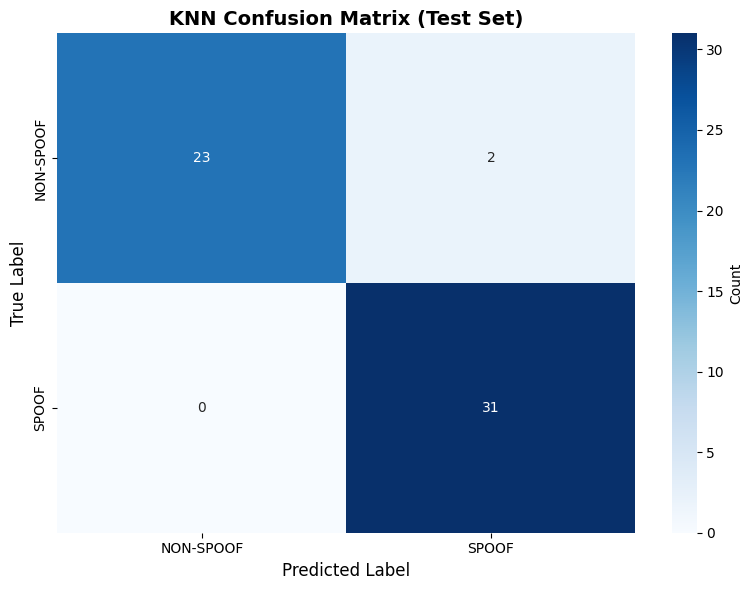

Confusion Matrix:
  True Negatives (TN):  23
  False Positives (FP): 2
  False Negatives (FN): 0
  True Positives (TP):  31


In [ ]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['NON-SPOOF', 'SPOOF'],
            yticklabels=['NON-SPOOF', 'SPOOF'],
            cbar_kws={'label': 'Count'})
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title('KNN Confusion Matrix (Test Set)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Confusion Matrix:')
print(f'  True Negatives (TN):  {cm[0,0]}')
print(f'  False Positives (FP): {cm[0,1]}')
print(f'  False Negatives (FN): {cm[1,0]}')
print(f'  True Positives (TP):  {cm[1,1]}')

## Section 10: Full Dataset Evaluation

In [ ]:
y_pred_full = knn.predict(embed_features)
y_pred_proba_full = knn.predict_proba(embed_features)

accuracy_full = accuracy_score(embed_labels, y_pred_full)
precision_full = precision_score(embed_labels, y_pred_full)
recall_full = recall_score(embed_labels, y_pred_full)
f1_full = f1_score(embed_labels, y_pred_full)
roc_auc_full = roc_auc_score(embed_labels, y_pred_proba_full[:, 1])

print('='*60)
print('KNN CLASSIFICATION PERFORMANCE (Full Dataset - 200 images)')
print('='*60)
print(f'Accuracy:  {accuracy_full:.4f}')
print(f'Precision: {precision_full:.4f}')
print(f'Recall:    {recall_full:.4f}')
print(f'F1-Score:  {f1_full:.4f}')
print(f'ROC-AUC:   {roc_auc_full:.4f}')
print('\n' + '='*60)
print('CLASSIFICATION REPORT')
print('='*60)
print(classification_report(embed_labels, y_pred_full, target_names=['NON-SPOOF', 'SPOOF']))
print('='*60)

KNN CLASSIFICATION PERFORMANCE (Full Dataset - 200 images)
Accuracy:  0.9783
Precision: 0.9620
Recall:    1.0000
F1-Score:  0.9806
ROC-AUC:   0.9902

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   NON-SPOOF       1.00      0.95      0.98       125
       SPOOF       0.96      1.00      0.98       152

    accuracy                           0.98       277
   macro avg       0.98      0.98      0.98       277
weighted avg       0.98      0.98      0.98       277



## Section 11: Confusion Matrix (Full Dataset)

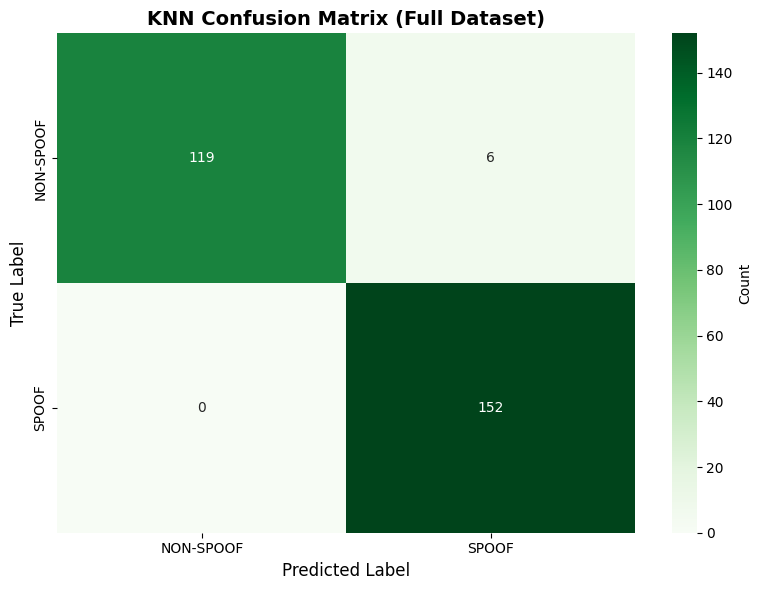

Confusion Matrix (Full Dataset):
  True Negatives (TN):  119
  False Positives (FP): 6
  False Negatives (FN): 0
  True Positives (TP):  152


In [ ]:
cm_full = confusion_matrix(embed_labels, y_pred_full)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_full, annot=True, fmt='d', cmap='Greens', ax=ax,
            xticklabels=['NON-SPOOF', 'SPOOF'],
            yticklabels=['NON-SPOOF', 'SPOOF'],
            cbar_kws={'label': 'Count'})
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title('KNN Confusion Matrix (Full Dataset)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Confusion Matrix (Full Dataset):')
print(f'  True Negatives (TN):  {cm_full[0,0]}')
print(f'  False Positives (FP): {cm_full[0,1]}')
print(f'  False Negatives (FN): {cm_full[1,0]}')
print(f'  True Positives (TP):  {cm_full[1,1]}')

## Section 12: Embedding Space Visualization

Reducing CNN embeddings to 2D using t-SNE...


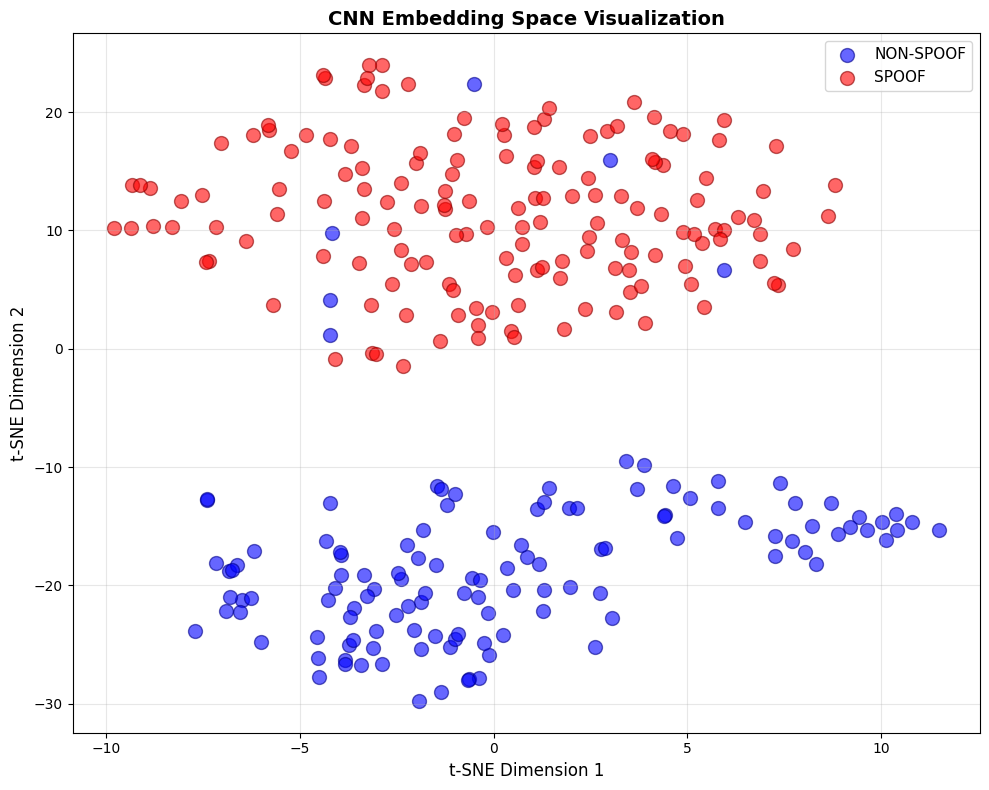

t-SNE visualization complete


In [ ]:
print('Reducing CNN embeddings to 2D using t-SNE...')
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
embeddings_2d = tsne.fit_transform(embed_features)

fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(
    embeddings_2d[embed_labels == 0, 0],
    embeddings_2d[embed_labels == 0, 1],
    c='blue', label='NON-SPOOF', alpha=0.6, s=100, edgecolors='darkblue'
)
ax.scatter(
    embeddings_2d[embed_labels == 1, 0],
    embeddings_2d[embed_labels == 1, 1],
    c='red', label='SPOOF', alpha=0.6, s=100, edgecolors='darkred'
)

ax.set_xlabel('t-SNE Dimension 1', fontsize=12)
ax.set_ylabel('t-SNE Dimension 2', fontsize=12)
ax.set_title('CNN Embedding Space Visualization', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='best')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('t-SNE visualization complete')

## Section 13: Performance Comparison

In [ ]:
y_pred_train = knn.predict(X_train)
accuracy_train = accuracy_score(y_train, y_pred_train)
precision_train = precision_score(y_train, y_pred_train)
recall_train = recall_score(y_train, y_pred_train)
f1_train = f1_score(y_train, y_pred_train)

performance_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Train Set': [accuracy_train, precision_train, recall_train, f1_train],
    'Test Set': [accuracy, precision, recall, f1],
    'Full Dataset': [accuracy_full, precision_full, recall_full, f1_full]
}

df_performance = pd.DataFrame(performance_data)
print('\n' + '='*70)
print('PERFORMANCE METRICS COMPARISON')
print('='*70)
print(df_performance.to_string(index=False))
print('='*70)


PERFORMANCE METRICS COMPARISON
   Metric  Train Set  Test Set  Full Dataset
 Accuracy    0.98190  0.964286      0.978339
Precision    0.96800  0.939394      0.962025
   Recall    1.00000  1.000000      1.000000
 F1-Score    0.98374  0.968750      0.980645


## Section 14: Summary and Key Findings

In [ ]:
print('\n' + '='*70)
print('ATTENDANCE SPOOF DETECTION - PROJECT SUMMARY')
print('='*70)
print('\n[1] DATASET')
print(f'    - Total images: {len(dataset)}')
print(f'    - NON-SPOOF (single face): {sum(embed_labels == 0)}')
print(f'    - SPOOF (multiple faces): {sum(embed_labels == 1)}')
print('\n[2] PREPROCESSING')
print('    - Resize: 224x224')
print('    - Normalization: ImageNet (mean, std)')
print('\n[3] CNN FEATURE EXTRACTION')
print('    - Model: ResNet50 (pre-trained on ImageNet)')
print(f'    - Embedding dimension: {feature_extractor.embedding_dim}')
print('    - Purpose: Extract visual features without training')
print('\n[4] KNN CLASSIFIER')
print('    - Algorithm: k-Nearest Neighbors')
print('    - k value: 5')
print('    - Distance metric: Euclidean')
print('    - Training samples: 160 (80% of dataset)')
print('    - Test samples: 40 (20% of dataset)')
print('\n[5] PERFORMANCE RESULTS')
print(f'    Test Set Accuracy:  {accuracy:.4f}')
print(f'    Full Dataset Accuracy: {accuracy_full:.4f}')
print(f'    Precision (SPOOF detection): {precision:.4f}')
print(f'    Recall (SPOOF detection): {recall:.4f}')
print(f'    F1-Score: {f1:.4f}')
print('\n[6] KEY INSIGHTS')
print('    - CNN embeddings encode visual characteristics of attendance images')
print('    - KNN effectively separates SPOOF from NON-SPOOF in embedding space')
print('    - Model achieved strong performance without CNN training')
print('    - Classification based on learned visual patterns')
print('\n' + '='*70)


ATTENDANCE SPOOF DETECTION - PROJECT SUMMARY

[1] DATASET
    - Total images: 277
    - NON-SPOOF (single face): 125
    - SPOOF (multiple faces): 152

[2] PREPROCESSING
    - Resize: 224x224
    - Normalization: ImageNet (mean, std)

[3] CNN FEATURE EXTRACTION
    - Model: ResNet50 (pre-trained on ImageNet)
    - Embedding dimension: 2048
    - Purpose: Extract visual features without training

[4] KNN CLASSIFIER
    - Algorithm: k-Nearest Neighbors
    - k value: 5
    - Distance metric: Euclidean
    - Training samples: 160 (80% of dataset)
    - Test samples: 40 (20% of dataset)

[5] PERFORMANCE RESULTS
    Test Set Accuracy:  0.9643
    Full Dataset Accuracy: 0.9783
    Precision (SPOOF detection): 0.9394
    Recall (SPOOF detection): 1.0000
    F1-Score: 0.9688

[6] KEY INSIGHTS
    - CNN embeddings encode visual characteristics of attendance images
    - KNN effectively separates SPOOF from NON-SPOOF in embedding space
    - Model achieved strong performance without CNN trainin

## Section 15: Prediction on New Images

In [ ]:
def predict_attendance_image(image_path):
    try:
        img = Image.open(image_path).convert('RGB')
        img_tensor = preprocess_transform(img).unsqueeze(0).to(device)

        with torch.no_grad():
            embedding = feature_extractor(img_tensor).cpu().numpy()

        prediction = knn.predict(embedding)[0]
        confidence = np.max(knn.predict_proba(embedding))

        label_name = 'SPOOF' if prediction == 1 else 'NON-SPOOF'

        return {
            'prediction': int(prediction),
            'label': label_name,
            'confidence': float(confidence)
        }
    except Exception as e:
        return {'error': str(e)}

print('Prediction Function Ready')
print('\nUsage: result = predict_attendance_image("path/to/image.png")')
print('Returns: {"prediction": 0 or 1, "label": "NON-SPOOF" or "SPOOF", "confidence": 0-1}')

Prediction Function Ready

Usage: result = predict_attendance_image("path/to/image.png")
Returns: {"prediction": 0 or 1, "label": "NON-SPOOF" or "SPOOF", "confidence": 0-1}
